# Klasterisasi Hierarki Produk

Agglomerative clustering pada fitur produk, divisualkan dengan dendrogram.

## 1. Muat & Agregasi

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('../data/Transactions.csv')
df['hour'] = pd.to_datetime(df['Time'], format='%H:%M:%S').dt.hour
df['Items'] = df['Items'].str.replace('Houesblend', 'Houseblend', regex=False)

ex = df.assign(Item=df['Items'].str.split(r',\s*')).explode('Item')
ex['Item'] = ex['Item'].str.strip()
ex['price'] = ex['TotalAmount'] / ex['TotalItem']

produk = ex.groupby('Item').agg(
    qty=('Item', 'size'),
    avg_price=('price', 'mean'),
    share_morning=('hour', lambda h: (h < 12).mean())).reset_index()

X = StandardScaler().fit_transform(produk[['qty', 'avg_price', 'share_morning']])
produk.shape

C:\Users\Radit\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\Radit\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


(94, 4)

## 2. Dendrogram

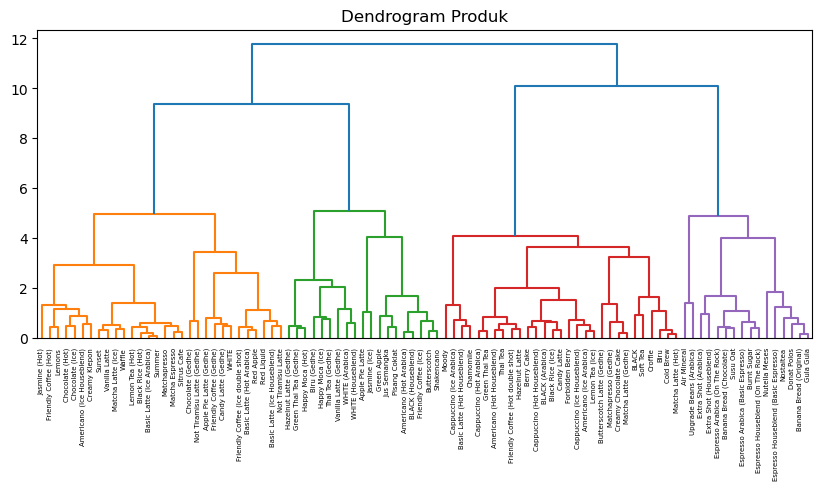

In [2]:
from scipy.cluster.hierarchy import dendrogram, linkage

plt.figure(figsize=(10, 4))
dendrogram(linkage(X, method='ward'), labels=produk['Item'].values, leaf_rotation=90)
plt.title('Dendrogram Produk')
plt.show()

## 3. Agglomerative Clustering

In [3]:
from sklearn.cluster import AgglomerativeClustering

model = AgglomerativeClustering(n_clusters=3, linkage='ward')
produk['klaster'] = model.fit_predict(X)
produk.groupby('klaster')[['qty', 'avg_price', 'share_morning']].mean().round(2)

,qty,avg_price,share_morning
klaster,,,
0,676.71,23586.03,0.27
1,652.88,11887.89,0.27
2,633.38,22346.75,0.26


## 4. Silhouette Score

In [4]:
from sklearn.metrics import silhouette_score

print('Silhouette:', round(silhouette_score(X, produk['klaster']), 3))

Silhouette: 0.274
